# Exercise 4: data types and missing values

The hobby station in Mechelen, HS01, also uploads its readings to an online weather network. That network
exports one reading per hour, with the time in UTC: `../../data/raw/hs01_hourly.csv`.

In [1]:
import pandas as pd

**4.1** Read `../../data/raw/hs01_hourly.csv` with `pd.read_csv`, without extra arguments. What goes wrong?
Fix it with the right arguments. The network writes `undefined` when a reading failed: make sure that
`temperature` and `humidity` are numbers. Check the data types.

Docs: [`pd.read_csv`](https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html)

In [2]:
pd.read_csv("../../data/raw/hs01_hourly.csv")

ParserError: Error tokenizing data. C error: Expected 1 fields in line 3, saw 2


pandas expects a comma between the columns. Here the columns are separated by `|`, and the comma is the
decimal sign. So pandas splits `15,8` in two, and finds a different number of columns on different lines.

In [3]:
measurements = pd.read_csv(
    "../../data/raw/hs01_hourly.csv", sep="|", decimal=",", na_values=["undefined"]
)
measurements

,time_utc,temperature,humidity
0,2023-01-01 00:00,16.0,49.0
1,2023-01-01 01:00,15.8,52.0
2,2023-01-01 02:00,15.6,55.0
3,2023-01-01 03:00,15.6,56.0
4,2023-01-01 04:00,14.5,61.0
...,...,...,...
8755,2023-12-31 19:00,8.4,76.0
8756,2023-12-31 20:00,8.4,80.0
8757,2023-12-31 21:00,7.2,84.0
8758,2023-12-31 22:00,8.6,77.0


In [4]:
measurements.dtypes

time_utc           str
temperature    float64
humidity       float64
dtype: object

**4.2** Also read `time_utc` as a date and time, and `humidity` as whole numbers that can be missing.
Check the data types.

Docs: [format codes](https://docs.python.org/3/library/datetime.html#format-codes)

In [5]:
measurements = pd.read_csv(
    "../../data/raw/hs01_hourly.csv",
    sep="|",
    decimal=",",
    na_values=["undefined"],
    dtype={"humidity": "Int64"},
    parse_dates=["time_utc"],
    date_format="%Y-%m-%d %H:%M",
)
measurements

,time_utc,temperature,humidity
0,2023-01-01 00:00:00,16.0,49
1,2023-01-01 01:00:00,15.8,52
2,2023-01-01 02:00:00,15.6,55
3,2023-01-01 03:00:00,15.6,56
4,2023-01-01 04:00:00,14.5,61
...,...,...,...
8755,2023-12-31 19:00:00,8.4,76
8756,2023-12-31 20:00:00,8.4,80
8757,2023-12-31 21:00:00,7.2,84
8758,2023-12-31 22:00:00,8.6,77


In [6]:
measurements.dtypes

time_utc       datetime64[us]
temperature           float64
humidity                Int64
dtype: object

**4.3** Plot the temperature with the time on the x-axis.

<Axes: xlabel='time_utc'>

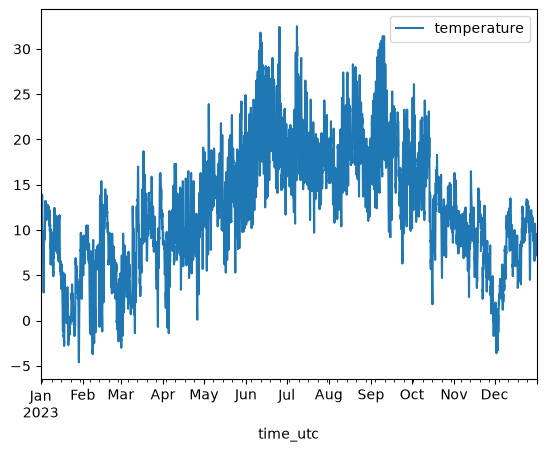

In [7]:
measurements.plot(x="time_utc", y="temperature")

**4.4** Convert the times to Belgian time (`Europe/Brussels`).

The file does not say that the times are in UTC, so pandas reads them as naive. `tz_localize` says they are
UTC, and `tz_convert` converts them to Belgian time.

In [8]:
belgian_time = (
    measurements["time_utc"].dt.tz_localize("UTC").dt.tz_convert("Europe/Brussels")
)
belgian_time.head(3)

0   2023-01-01 01:00:00+01:00
1   2023-01-01 02:00:00+01:00
2   2023-01-01 03:00:00+01:00
Name: time_utc, dtype: datetime64[us, Europe/Brussels]

**4.5** In Belgian time, how many readings are there on 14 June? On 26 March? And on 29 October? Where does
the difference come from?

In [9]:
(belgian_time.dt.normalize() == "2023-06-14").sum()

np.int64(24)

In [10]:
(belgian_time.dt.normalize() == "2023-03-26").sum()

np.int64(23)

In [11]:
(belgian_time.dt.normalize() == "2023-10-29").sum()

np.int64(25)

In [12]:
belgian_time[belgian_time.dt.normalize() == "2023-03-26"].head(4)

2015   2023-03-26 00:00:00+01:00
2016   2023-03-26 01:00:00+01:00
2017   2023-03-26 03:00:00+02:00
2018   2023-03-26 04:00:00+02:00
Name: time_utc, dtype: datetime64[us, Europe/Brussels]

A normal day has 24 readings, one per hour. On 26 March, summer time starts: the clock jumps from 02:00 to
03:00, so that day has only 23 hours in Belgium. On 29 October, it ends: the clock goes back from 03:00 to
02:00, so 02:00 comes twice and the day has 25 hours. In UTC, every day has 24 hours.

## Bonus

Suppose nobody had told you about `undefined`. Find the values in `temperature` that are not numbers.
Careful: in a text column, `decimal=","` has no effect.

Docs: [`str.replace`](https://pandas.pydata.org/docs/reference/api/pandas.Series.str.replace.html) (not in the slides)

In [13]:
raw = pd.read_csv("../../data/raw/hs01_hourly.csv", sep="|", decimal=",")
temperature = raw["temperature"]
as_number = pd.to_numeric(temperature.str.replace(",", "."), errors="coerce")
temperature[~temperature.isna() & as_number.isna()].unique()

<ArrowStringArray>
['undefined']
Length: 1, dtype: str